### Esempio Pratico: Calcolo Passo Passo

Consideriamo un piccolo dataset scolastico con 4 studenti divisi in 2 classi ($X$), di cui registriamo il voto finale ($Y$):
*   **Classe A ($X=A$):** Voti 4, 6
*   **Classe B ($X=B$):** Voti 8, 12

Applichiamo la Legge della Varianza Totale calcolando manualmente i due blocchi.

**1. Varianza Non Spiegata (Intra-gruppo): $E[Var(Y|X)]$**
Calcoliamo la varianza interna di ogni singola classe rispetto alla sua stessa media:
*   Media A = 5 $\rightarrow$ Varianza A = $\frac{(4-5)^2 + (6-5)^2}{2} = 1$
*   Media B = 10 $\rightarrow$ Varianza B = $\frac{(8-10)^2 + (12-10)^2}{2} = 4$
*   Essendo i gruppi di uguale dimensione, il Valore Atteso (media) delle varianze è: $\frac{1 + 4}{2} = 2.5$

**2. Varianza Spiegata (Tra-gruppi): $Var(E[Y|X])$**
Calcoliamo quanto le medie dei singoli gruppi si discostano dalla media globale di tutti gli studenti (che è 7.5):
*   Varianza delle Medie: $\frac{(5-7.5)^2 + (10-7.5)^2}{2} = 6.25$

**Somma e Verifica sulla Varianza Totale:**
*   Somma delle componenti (Legge di Eve): $2.5 + 6.25 = 8.75$
*   Calcolo diretto della varianza su tutti i voti aggregati [4, 6, 8, 12]: $\frac{(4-7.5)^2 + (6-7.5)^2 + (8-7.5)^2 + (12-7.5)^2}{4} = 8.75$

TypeError: 'module' object is not callable

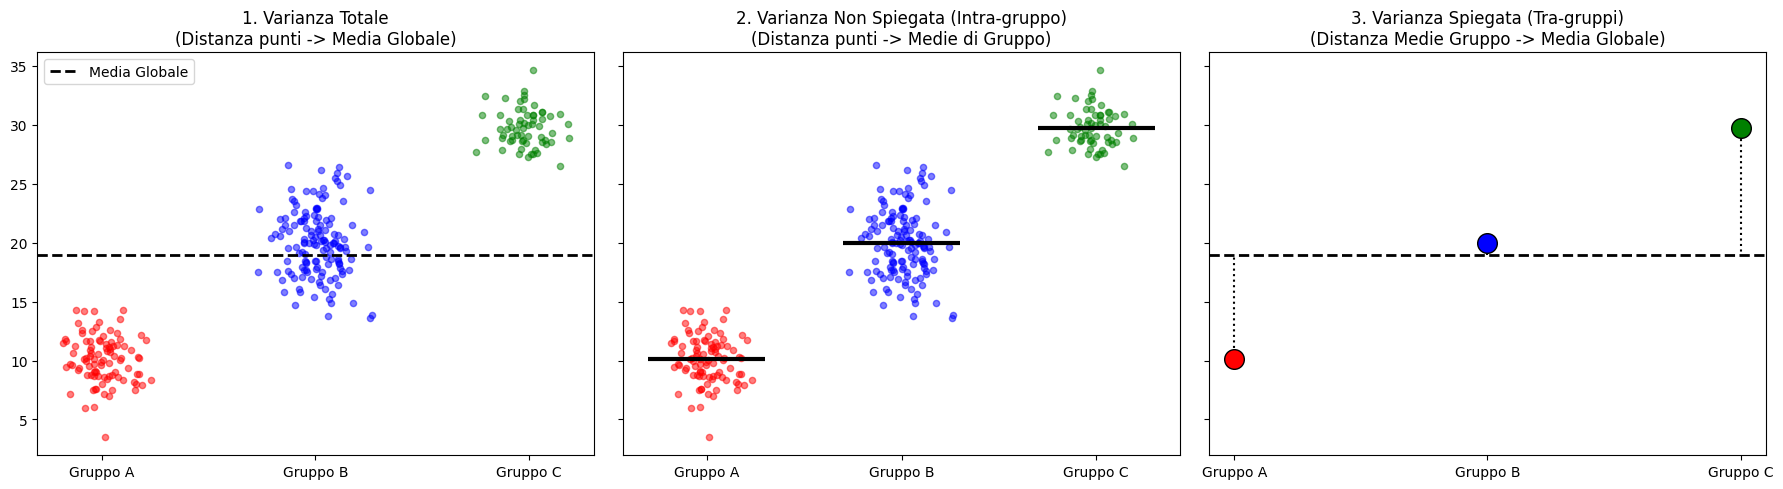

In [12]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Generazione dei dati (come nell'esempio precedente)
np.random.seed(42)
n_samples = 300

X = np.random.choice(['Gruppo A', 'Gruppo B', 'Gruppo C'], size=n_samples, p=[0.3, 0.5, 0.2])

Y = np.zeros(n_samples)
Y[X == 'Gruppo A'] = np.random.normal(loc=10, scale=2, size=sum(X == 'Gruppo A'))
Y[X == 'Gruppo B'] = np.random.normal(loc=20, scale=3, size=sum(X == 'Gruppo B'))
Y[X == 'Gruppo C'] = np.random.normal(loc=30, scale=1.5, size=sum(X == 'Gruppo C'))

# Calcoli delle medie e varianze
media_totale = np.mean(Y)
var_totale = np.var(Y)

gruppi = ['Gruppo A', 'Gruppo B', 'Gruppo C']
medie_gruppi = {g: np.mean(Y[X == g]) for g in gruppi}
var_gruppi = {g: np.var(Y[X == g]) for g in gruppi}
pesi_gruppi = {g: sum(X == g)/n_samples for g in gruppi}

# Varianza Non Spiegata (Intra-gruppo)
var_non_spiegata = sum(var_gruppi[g] * pesi_gruppi[g] for g in gruppi)

# Varianza Spiegata (Tra-gruppi)
media_delle_medie = sum(medie_gruppi[g] * pesi_gruppi[g] for g in gruppi)
var_spiegata = sum(((medie_gruppi[g] - media_delle_medie)**2) * pesi_gruppi[g] for g in gruppi)

# 2. Creazione dei Grafici Visivi
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

# Colori per i gruppi
colors = {'Gruppo A': 'red', 'Gruppo B': 'blue', 'Gruppo C': 'green'}
x_jitter = np.random.normal(0, 0.1, size=n_samples) # per visualizzare meglio i punti

# Plot 1: Varianza Totale (Punti vs Media Globale)
for g in gruppi:
    mask = X == g
    x_pos = [gruppi.index(g)] * sum(mask) + x_jitter[mask]
    axes[0].scatter(x_pos, Y[mask], color=colors[g], alpha=0.5, s=20)
axes[0].axhline(media_totale, color='black', linestyle='--', linewidth=2, label='Media Globale')
axes[0].set_title("1. Varianza Totale\n(Distanza punti -> Media Globale)")
axes[0].set_xticks([0, 1, 2])
axes[0].set_xticklabels(gruppi)
axes[0].legend()

# Plot 2: Varianza Non Spiegata (Punti vs Medie di Gruppo)
for g in gruppi:
    mask = X == g
    x_pos = [gruppi.index(g)] * sum(mask) + x_jitter[mask]
    axes[1].scatter(x_pos, Y[mask], color=colors[g], alpha=0.5, s=20)
    # Linea della media del gruppo
    axes[1].hlines(medie_gruppi[g], xmin=gruppi.index(g)-0.3, xmax=gruppi.index(g)+0.3, 
                   colors='black', linewidth=3, label=f'Media {g}' if g == 'Gruppo A' else "")
axes[1].set_title("2. Varianza Non Spiegata (Intra-gruppo)\n(Distanza punti -> Medie di Gruppo)")
axes[1].set_xticks([0, 1, 2])
axes[1].set_xticklabels(gruppi)

# Plot 3: Varianza Spiegata (Medie di Gruppo vs Media Globale)
for g in gruppi:
    axes[2].scatter(gruppi.index(g), medie_gruppi[g], color=colors[g], s=200, edgecolor='black', zorder=5)
    axes[2].plot([gruppi.index(g), gruppi.index(g)], [medie_gruppi[g], media_totale], color='black', linestyle=':')
axes[2].axhline(media_totale, color='black', linestyle='--', linewidth=2, label='Media Globale')
axes[2].set_title("3. Varianza Spiegata (Tra-gruppi)\n(Distanza Medie Gruppo -> Media Globale)")
axes[2].set_xticks([0, 1, 2])
axes[2].set_xticklabels(gruppi)

plt.tight_layout()
plt('varianza_visiva.png', dpi=150)
plt.close()

print(f"Var Totale: {var_totale:.2f}")
print(f"Var Non Spiegata: {var_non_spiegata:.2f}")
print(f"Var Spiegata: {var_spiegata:.2f}")

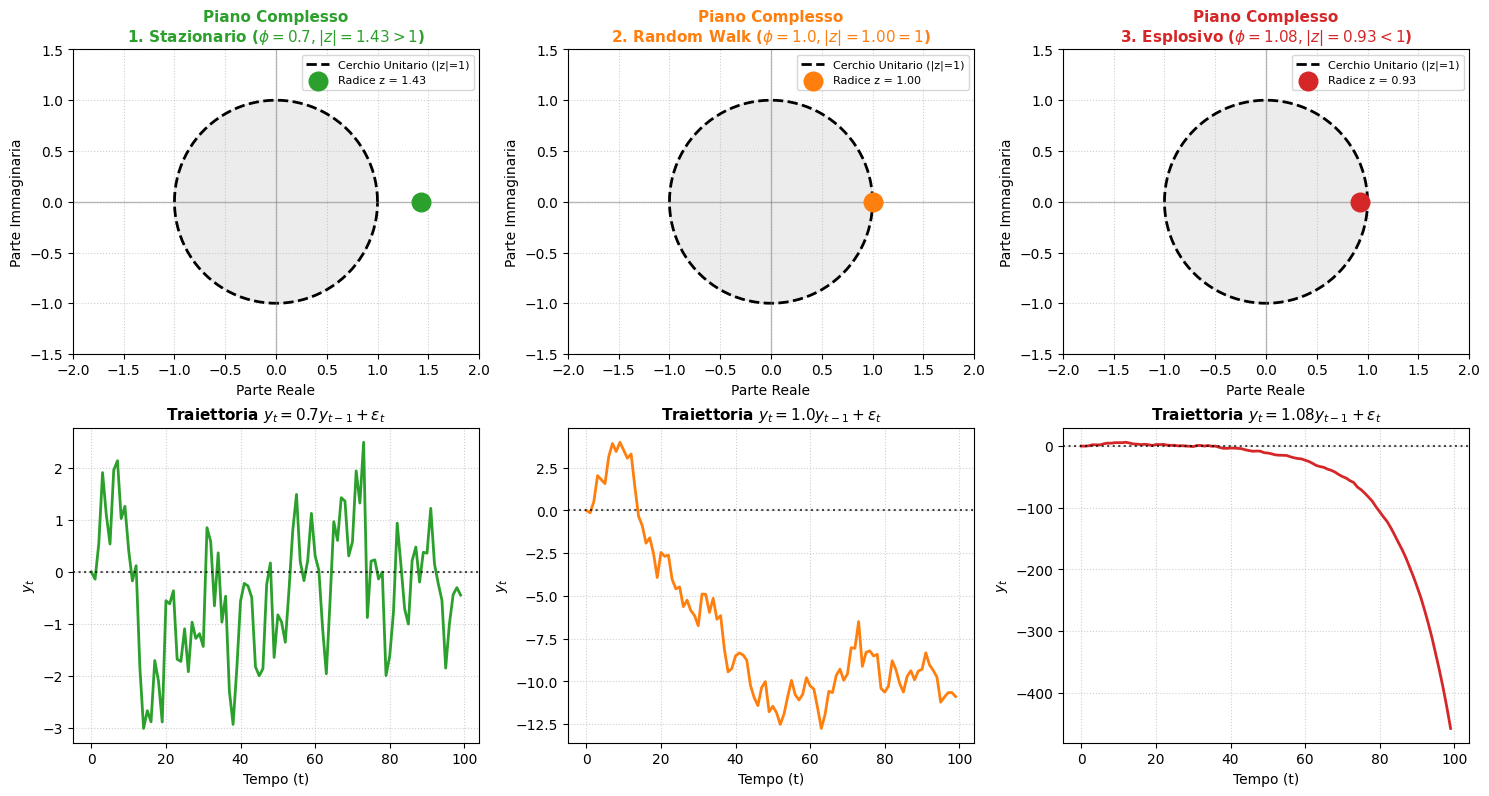

In [13]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
T = 100
e = np.random.normal(0, 1, T)

# Valori di phi e relative etichette
phis = [0.7, 1.0, 1.08]
labels = [
    r'1. Stazionario ($\phi=0.7, |z|=1.43 > 1$)',
    r'2. Random Walk ($\phi=1.0, |z|=1.00 = 1$)',
    r'3. Esplosivo ($\phi=1.08, |z|=0.93 < 1$)'
]
colors = ['#2ca02c', '#ff7f0e', '#d62728']

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

# Generazione circonferenza del cerchio unitario
theta = np.linspace(0, 2*np.pi, 200)
unit_circle_x = np.cos(theta)
unit_circle_y = np.sin(theta)

for i, phi in enumerate(phis):
    z = 1.0 / phi
    
    # 1. Piano Complesso
    ax_complex = axes[0, i]
    ax_complex.plot(unit_circle_x, unit_circle_y, 'k--', linewidth=2, label='Cerchio Unitario (|z|=1)')
    ax_complex.fill(unit_circle_x, unit_circle_y, color='gray', alpha=0.15)
    ax_complex.scatter([z], [0], color=colors[i], s=180, zorder=5, label=f'Radice z = {z:.2f}')
    ax_complex.axhline(0, color='gray', alpha=0.5, linewidth=1)
    ax_complex.axvline(0, color='gray', alpha=0.5, linewidth=1)
    ax_complex.set_xlim(-2.0, 2.0)
    ax_complex.set_ylim(-1.5, 1.5)
    ax_complex.set_aspect('equal')
    ax_complex.set_title(f'Piano Complesso\n{labels[i]}', fontsize=11, fontweight='bold', color=colors[i])
    ax_complex.set_xlabel('Parte Reale')
    ax_complex.set_ylabel('Parte Immaginaria')
    ax_complex.legend(loc='upper right', fontsize=8)
    ax_complex.grid(True, linestyle=':', alpha=0.6)
    
    # 2. Serie Storica
    ax_ts = axes[1, i]
    y = np.zeros(T)
    for t in range(1, T):
        y[t] = phi * y[t-1] + e[t]
        
    ax_ts.plot(y, color=colors[i], linewidth=2)
    ax_ts.axhline(0, color='black', linestyle=':', alpha=0.7)
    ax_ts.set_title(f'Traiettoria $y_t = {phi} y_{{t-1}} + \epsilon_t$', fontsize=11, fontweight='bold')
    ax_ts.set_xlabel('Tempo (t)')
    ax_ts.set_ylabel('$y_t$')
    ax_ts.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

## Trasformare un ARMA(1,1) in una somma di Shock (MA infinito)

Abbiamo visto matematicamente che un processo ARMA(1,1) può essere "srotolato" per dipendere solo ed esclusivamente dalle notizie (shock) passate. 
La formula che ci dice **quanto pesa oggi** una notizia di $j$ giorni fa è:

*   **Lag 0 (Oggi):** Il peso è sempre $1$. (La notizia di oggi impatta al 100%).
*   **Lag j (Passato):** Il peso è $\psi_j = \phi^{j-1}(\phi + \psi)$.

Scriviamo una funzione Python per calcolare questi pesi e visualizzare come le notizie invecchiano e perdono importanza nel tempo.

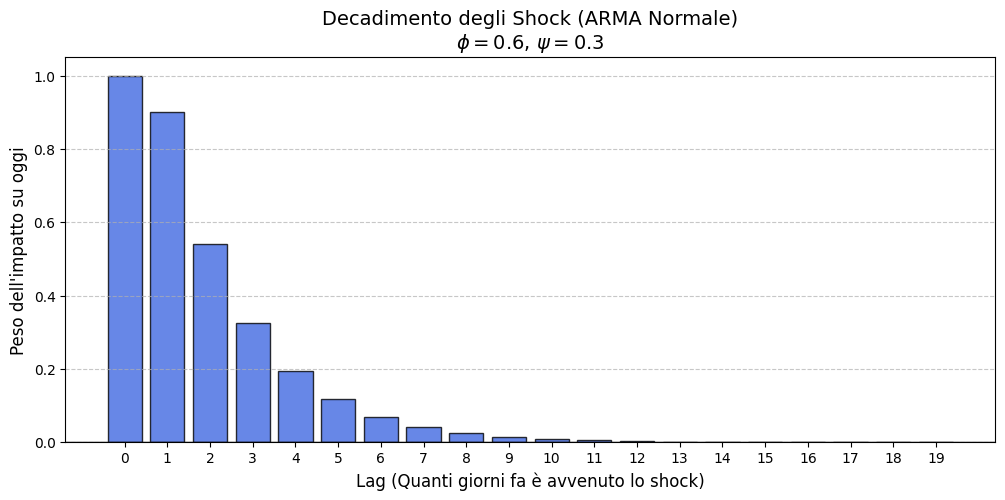

In [14]:
import numpy as np
import matplotlib.pyplot as plt

def calcola_pesi_ma_infinito(phi, psi, max_lags=20):
    """
    Calcola i coefficienti (pesi) per trasformare un ARMA(1,1) in un MA(infinito).
    Mostra l'impatto di uno shock passato sul prezzo di oggi.
    """
    pesi = np.zeros(max_lags)
    
    # Lo shock di oggi (lag 0) ha sempre un impatto diretto di 1
    pesi[0] = 1.0 
    
    # Calcolo del peso per tutti gli shock passati (lag da 1 in poi)
    for j in range(1, max_lags):
        pesi[j] = (phi**(j-1)) * (phi + psi)
        
    return pesi

# --- SIMULAZIONE 1: ARMA(1,1) STANDARD ---
# Scegliamo un'inerzia moderata (phi) e un eco positivo (psi)
phi_normale = 0.6
psi_normale = 0.3

pesi_normali = calcola_pesi_ma_infinito(phi_normale, psi_normale)

# Visualizzazione
plt.figure(figsize=(12, 5))
plt.bar(range(20), pesi_normali, color='royalblue', edgecolor='black', alpha=0.8)
plt.axhline(0, color='black', linewidth=1)
plt.title(f"Decadimento degli Shock (ARMA Normale)\n$\phi={phi_normale}$, $\psi={psi_normale}$", fontsize=14)
plt.xlabel("Lag (Quanti giorni fa è avvenuto lo shock)", fontsize=12)
plt.ylabel("Peso dell'impatto su oggi", fontsize=12)
plt.xticks(range(20))
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

### Il Caso Limite: White Noise (Rumore Bianco)

Cosa succede se specifichiamo male il nostro modello e inseriamo un parametro AR ($\phi$) e un parametro MA ($\psi$) che hanno forze **esattamente uguali e contrarie**?

Matematicamente poniamo $\phi = -\psi$. 
Il risultato è la **Cancellazione delle Radici Comuni**: l'inerzia viene uccisa dall'eco. Il modello perde ogni memoria del passato e l'unico shock che conta rimane quello di oggi, trasformando la serie in un puro rumore casuale.

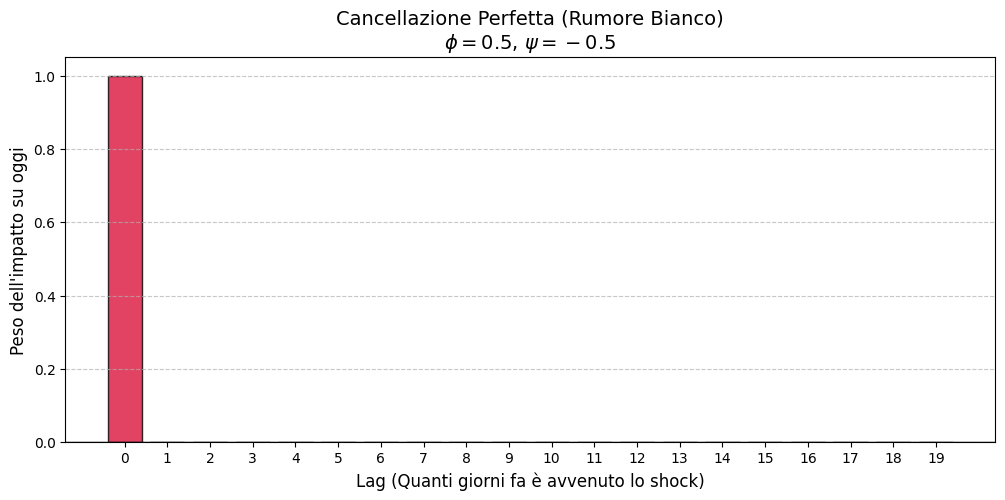

Valori esatti dei pesi calcolati dal programma:
Lag 0: 1.0
Lag 1: 0.0
Lag 2: 0.0
Lag 3: 0.0
Lag 4: 0.0


In [15]:
# --- SIMULAZIONE 2: PARAMETRIZZAZIONE RIDONDANTE ---
# Impostiamo psi in modo che sia l'esatto opposto di phi
phi_wn = 0.5
psi_wn = -0.5

pesi_wn = calcola_pesi_ma_infinito(phi_wn, psi_wn)

# Visualizzazione
plt.figure(figsize=(12, 5))
plt.bar(range(20), pesi_wn, color='crimson', edgecolor='black', alpha=0.8)
plt.axhline(0, color='black', linewidth=1)
plt.title(f"Cancellazione Perfetta (Rumore Bianco)\n$\phi={phi_wn}$, $\psi={psi_wn}$", fontsize=14)
plt.xlabel("Lag (Quanti giorni fa è avvenuto lo shock)", fontsize=12)
plt.ylabel("Peso dell'impatto su oggi", fontsize=12)
plt.xticks(range(20))
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# Stampiamo i valori per conferma
print("Valori esatti dei pesi calcolati dal programma:")
for lag, peso in enumerate(pesi_wn[:5]): # Stampiamo solo i primi 5 lag
    print(f"Lag {lag}: {peso}")

### La Struttura dell'Autocorrelazione nell'ARMA(1,1)

Nel modello $y_t = \phi y_{t-1} + \epsilon_t + \psi \epsilon_{t-1}$, l'autocorrelazione ($\rho_k$) segue regole fisse:

1.  **Lag 0 ($\rho_0 = 1$):** La correlazione di oggi con se stesso è sempre 100%.
2.  **Lag 1 ($\rho_1$):** È una formula complessa che unisce AR e MA: $\rho_1 = \frac{(\phi + \psi)(1 + \phi\psi)}{1 + 2\phi\psi + \psi^2}$
3.  **Lag 2+ ($\rho_k$ con $k \ge 2$):** Diventa un decadimento esponenziale standard: $\rho_k = \phi \cdot \rho_{k-1}$

Il parametro MA ($\psi$) "sporca" solo il primissimo salto (da Lag 0 a Lag 1). Dopodiché, è il parametro AR ($\phi$) a guidare la discesa verso lo zero.

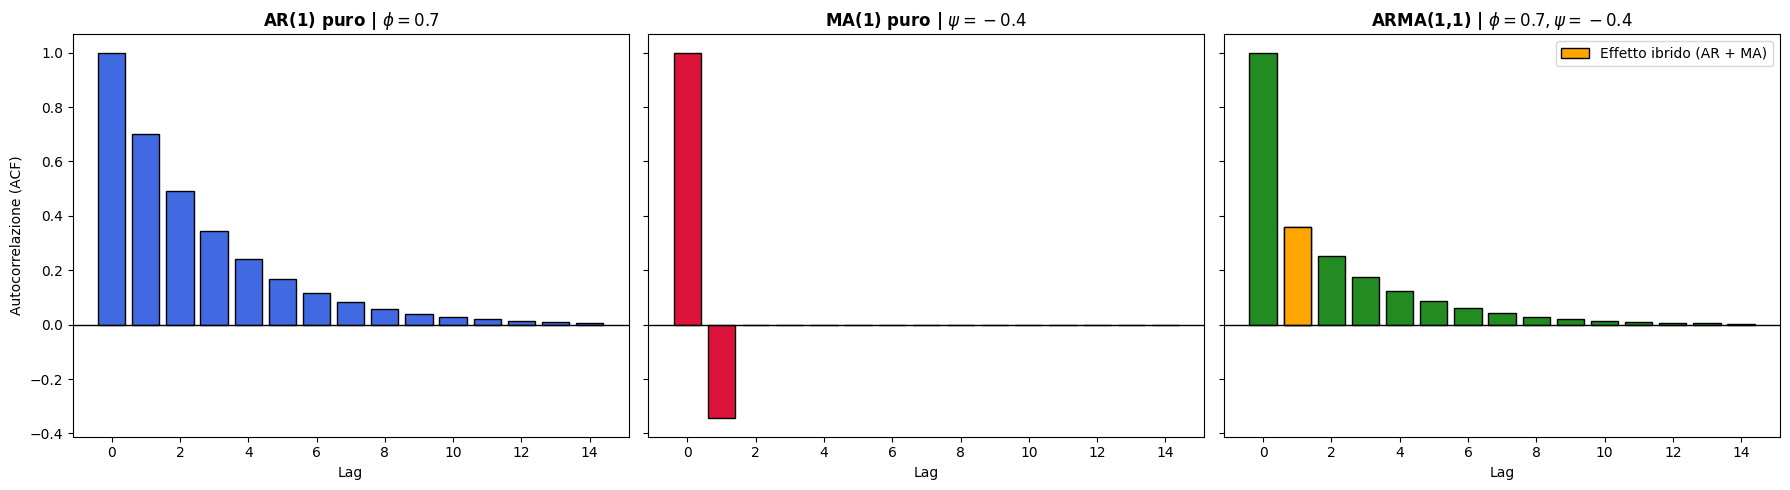

--- Valori ARMA(1,1) ---
Varianza Totale (Gamma_0): 1.1765
Autocovarianza Lag 1 (Gamma_1): 0.4235
Autocorrelazione Lag 1 (Rho_1): 0.3600


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.arima_process import ArmaProcess

# 1. Definiamo i parametri (es. inerzia positiva, shock negativo)
phi = 0.7   # Parametro AR
psi = -0.4  # Parametro MA

# Attenzione: statsmodels richiede che i parametri AR abbiano il segno invertito 
# (convenzione del polinomio caratteristico 1 - phi*L = 0)
ar_params = np.array([1, -phi])
ma_params = np.array([1, psi])

# Creiamo i tre processi teorici
processo_ar = ArmaProcess(ar_params, np.array([1]))        # Solo AR(1)
processo_ma = ArmaProcess(np.array([1]), ma_params)        # Solo MA(1)
processo_arma = ArmaProcess(ar_params, ma_params)          # ARMA(1,1)

# Estraiamo le Autocorrelazioni (ACF) teoriche per i primi 15 lag
lags = 15
acf_ar = processo_ar.acf(lags)
acf_ma = processo_ma.acf(lags)
acf_arma = processo_arma.acf(lags)

# 2. Creiamo il grafico a barre per confrontarli
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
x = np.arange(lags)

# Grafico 1: AR(1)
axes[0].bar(x, acf_ar, color='royalblue', edgecolor='black')
axes[0].axhline(0, color='black', lw=1)
axes[0].set_title(f"AR(1) puro | $\phi={phi}$", fontweight='bold')
axes[0].set_xlabel("Lag")
axes[0].set_ylabel("Autocorrelazione (ACF)")

# Grafico 2: MA(1)
axes[1].bar(x, acf_ma, color='crimson', edgecolor='black')
axes[1].axhline(0, color='black', lw=1)
axes[1].set_title(f"MA(1) puro | $\psi={psi}$", fontweight='bold')
axes[1].set_xlabel("Lag")

# Grafico 3: ARMA(1,1)
axes[2].bar(x, acf_arma, color='forestgreen', edgecolor='black')
axes[2].axhline(0, color='black', lw=1)
# Evidenziamo il Lag 1 (il punto critico)
axes[2].bar(1, acf_arma[1], color='orange', edgecolor='black', label="Effetto ibrido (AR + MA)")
axes[2].set_title(f"ARMA(1,1) | $\phi={phi}, \psi={psi}$", fontweight='bold')
axes[2].set_xlabel("Lag")
axes[2].legend()

plt.tight_layout()
plt.show()

# Extra: Calcolo dell'Autocovarianza per l'ARMA(1,1)
# L'autocovarianza è l'ACF moltiplicata per la Varianza (Gamma_0)
acov_arma = processo_arma.acovf(lags)
print(f"--- Valori ARMA(1,1) ---")
print(f"Varianza Totale (Gamma_0): {acov_arma[0]:.4f}")
print(f"Autocovarianza Lag 1 (Gamma_1): {acov_arma[1]:.4f}")
print(f"Autocorrelazione Lag 1 (Rho_1): {acf_arma[1]:.4f}")

### La Dinamica dell'Autocovarianza in un ARMA(1,1)

Questo grafico dimostra fisicamente le formule matematiche dell'autocovarianza $\gamma_k$ nel modello $y_t = \phi y_{t-1} + \epsilon_t + \psi \epsilon_{t-1}$:

1.  **$\gamma_0$ (Lag 0):** È il punto di partenza (la Varianza). È l'energia totale del sistema.
2.  **$\gamma_1$ (Lag 1):** È il punto ibrido. Subisce sia la spinta dell'inerzia ($\phi \gamma_0$) sia l'impatto diretto dello shock di ieri ($\psi \sigma^2$).
3.  **$\gamma_k$ (Lag 2+):** È la zona di puro decadimento AR. Da qui in poi l'eco dello shock svanisce e ogni barra è semplicemente una frazione ($\phi$) della barra precedente.

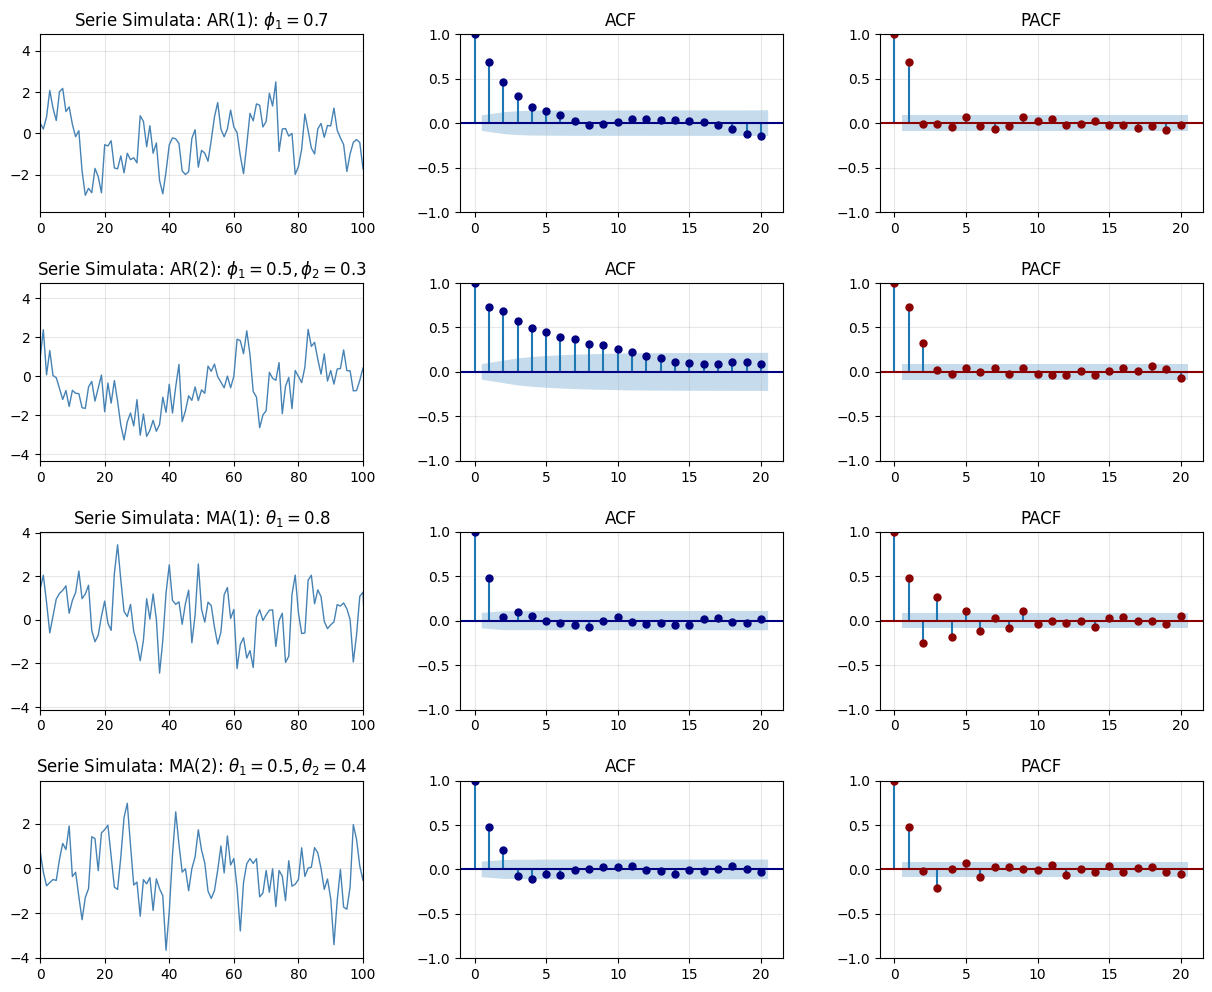

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.arima_process import ArmaProcess
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Impostazioni di riproducibilità e stile
np.random.seed(42)
plt.style.use('default')

# Definizione dei parametri per i processi
# statsmodels richiede che il coefficiente di ritardo 0 sia 1
# Per AR: [1, -phi_1, -phi_2, ...]
# Per MA: [1, theta_1, theta_2, ...]
processes = {
    'AR(1): $\phi_1=0.7$': {'ar': np.array([1, -0.7]), 'ma': np.array([1])},
    'AR(2): $\phi_1=0.5, \phi_2=0.3$': {'ar': np.array([1, -0.5, -0.3]), 'ma': np.array([1])},
    'MA(1): $\\theta_1=0.8$': {'ar': np.array([1]), 'ma': np.array([1, 0.8])},
    'MA(2): $\\theta_1=0.5, \\theta_2=0.4$': {'ar': np.array([1]), 'ma': np.array([1, 0.5, 0.4])}
}

n_samples = 500
lags = 20

# Creazione della griglia di grafici (4 righe, 3 colonne)
fig, axes = plt.subplots(len(processes), 3, figsize=(15, 12))
plt.subplots_adjust(hspace=0.4, wspace=0.3)

for i, (title, params) in enumerate(processes.items()):
    # Simulazione del processo
    arma_process = ArmaProcess(params['ar'], params['ma'])
    simulated_data = arma_process.generate_sample(nsample=n_samples)
    
    # 1. Plot della Serie Storica
    axes[i, 0].plot(simulated_data, color='steelblue', linewidth=1)
    axes[i, 0].set_title(f'Serie Simulata: {title}')
    axes[i, 0].set_xlim(0, 100) # Mostriamo solo i primi 100 punti per chiarezza
    axes[i, 0].grid(alpha=0.3)
    
    # 2. Plot ACF (Auto-Correlation Function)
    plot_acf(simulated_data, ax=axes[i, 1], lags=lags, title='ACF', color='navy')
    axes[i, 1].grid(alpha=0.3)
    
    # 3. Plot PACF (Partial Auto-Correlation Function)
    plot_pacf(simulated_data, ax=axes[i, 2], lags=lags, title='PACF', color='darkred', method='ywm')
    axes[i, 2].grid(alpha=0.3)

plt.show()

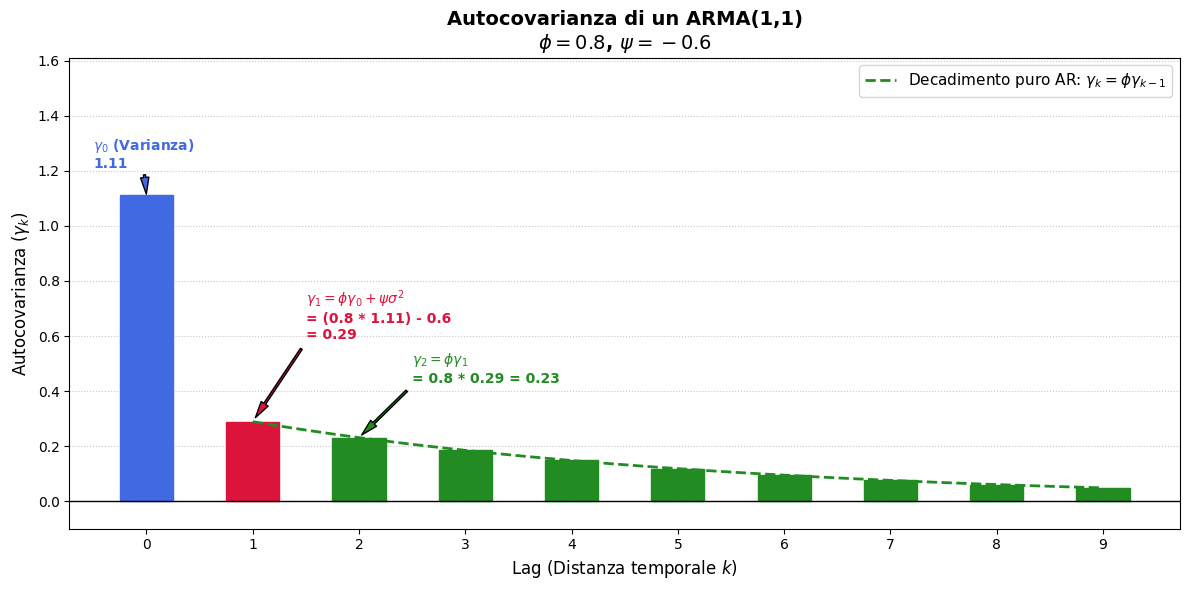

--- VERIFICA MATEMATICA DEI CALCOLI ---
Gamma 0 (estratto dal modello): 1.1111
Gamma 1 (calcolato a mano: phi*gamma0 + psi*sigma2): 0.2889
Gamma 1 (estratto dal modello): 0.2889 -> Coincidono? True
Gamma 2 (calcolato a mano: phi*gamma1): 0.2311
Gamma 2 (estratto dal modello): 0.2311 -> Coincidono? True


In [ ]:
# "indice custom" è implementare un modello a Stati Nascosti di Markov (Hidden Markov Model - HMM)
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.arima_process import ArmaProcess

# 1. Impostiamo i parametri
# Usiamo un'inerzia forte (phi=0.8) e uno shock negativo (psi=-0.6) 
# per rendere il "gradino" del Lag 1 molto evidente visivamente.
phi = 0.8
psi = -0.6
sigma2 = 1.0 # Varianza fissa dello shock (rumore bianco)

ar_params = np.array([1, -phi])
ma_params = np.array([1, psi])

# Creiamo il processo teorico ARMA(1,1)
processo_arma = ArmaProcess(ar_params, ma_params)

# Estraiamo l'Autocovarianza (Gamma) per i primi 10 lag
lags = 10
gamma = processo_arma.acovf(lags)

# 2. Creazione del Grafico
fig, ax = plt.subplots(figsize=(12, 6))

# Disegniamo le barre dell'autocovarianza
x = np.arange(lags)
bars = ax.bar(x, gamma, color='lightgray', edgecolor='black', width=0.5, zorder=2)

# --- Evidenziamo le 3 Fasi Matematiche ---

# FASE 1: Lag 0 (Varianza Totale)
bars[0].set_color('royalblue')
ax.annotate(f"$\gamma_0$ (Varianza)\n{gamma[0]:.2f}", 
            xy=(0, gamma[0]), xytext=(-0.5, gamma[0] + 0.1),
            arrowprops=dict(facecolor='royalblue', shrink=0.05, width=1.5, headwidth=6),
            fontsize=10, fontweight='bold', color='royalblue')

# FASE 2: Lag 1 (L'anomalia ibrida AR + MA)
bars[1].set_color('crimson')
testo_lag1 = f"$\gamma_1 = \phi\gamma_0 + \psi\sigma^2$\n= (0.8 * {gamma[0]:.2f}) - 0.6\n= {gamma[1]:.2f}"
ax.annotate(testo_lag1, 
            xy=(1, gamma[1]), xytext=(1.5, gamma[1] + 0.3),
            arrowprops=dict(facecolor='crimson', shrink=0.05, width=1.5, headwidth=6),
            fontsize=10, fontweight='bold', color='crimson')

# FASE 3: Lag 2+ (Il puro decadimento esponenziale)
for i in range(2, lags):
    bars[i].set_color('forestgreen')

# Disegniamo la curva del decadimento (che parte da Lag 1) per dimostrare la regola fissa
x_curve = np.linspace(1, lags-1, 100)
# La formula del decadimento continuo partendo dal punto gamma[1]
y_curve = gamma[1] * (phi ** (x_curve - 1))
ax.plot(x_curve, y_curve, color='forestgreen', linestyle='--', linewidth=2, zorder=3, 
        label="Decadimento puro AR: $\gamma_k = \phi \gamma_{k-1}$")

# Annotazione per il Lag 2 per mostrare il legame col Lag 1
ax.annotate(f"$\gamma_2 = \phi\gamma_1$\n= 0.8 * {gamma[1]:.2f} = {gamma[2]:.2f}", 
            xy=(2, gamma[2]), xytext=(2.5, gamma[2] + 0.2),
            arrowprops=dict(facecolor='forestgreen', shrink=0.05, width=1.5, headwidth=6),
            fontsize=10, fontweight='bold', color='forestgreen')

# Estetica del grafico
ax.axhline(0, color='black', lw=1)
ax.set_title(f"Autocovarianza di un ARMA(1,1)\n$\phi={phi}$, $\psi={psi}$", fontsize=14, fontweight='bold')
ax.set_xlabel("Lag (Distanza temporale $k$)", fontsize=12)
ax.set_ylabel("Autocovarianza ($\gamma_k$)", fontsize=12)
ax.set_xticks(x)
ax.set_ylim(-0.1, gamma[0] + 0.5)
ax.grid(axis='y', linestyle=':', alpha=0.7, zorder=1)
ax.legend(loc='upper right', fontsize=11)

plt.tight_layout()
plt.show()

# 3. Stampa di verifica matematica nella console
print("--- VERIFICA MATEMATICA DEI CALCOLI ---")
print(f"Gamma 0 (estratto dal modello): {gamma[0]:.4f}")

gamma_1_manuale = phi * gamma[0] + (psi * sigma2)
print(f"Gamma 1 (calcolato a mano: phi*gamma0 + psi*sigma2): {gamma_1_manuale:.4f}")
print(f"Gamma 1 (estratto dal modello): {gamma[1]:.4f} -> Coincidono? {np.isclose(gamma_1_manuale, gamma[1])}")

gamma_2_manuale = phi * gamma[1]
print(f"Gamma 2 (calcolato a mano: phi*gamma1): {gamma_2_manuale:.4f}")
print(f"Gamma 2 (estratto dal modello): {gamma[2]:.4f} -> Coincidono? {np.isclose(gamma_2_manuale, gamma[2])}")

## Algoritmo State-Space per l'Integrazione delle Recessioni
In questo esperimento simuliamo 200 mesi di "crescita economica" (dati osservati $y_t$). 
Creiamo artificialmente due "Regimi" (Stati nascosti $S_t$):
*   **Stato 0 (Espansione):** Crescita media positiva (+0.5%), bassa volatilità.
*   **Stato 1 (Recessione):** Crescita media negativa (-1.0%), alta volatilità.

Chiederemo al modello Markov-Switching di `statsmodels` (che applica la logica del Filtro di Hamilton/Kalman per stati discreti) di indovinare le recessioni usando solo la serie $y_t$, estraendo le probabilità filtrate, le probabilità "smoothed" (riviste a posteriori) e le previsioni.

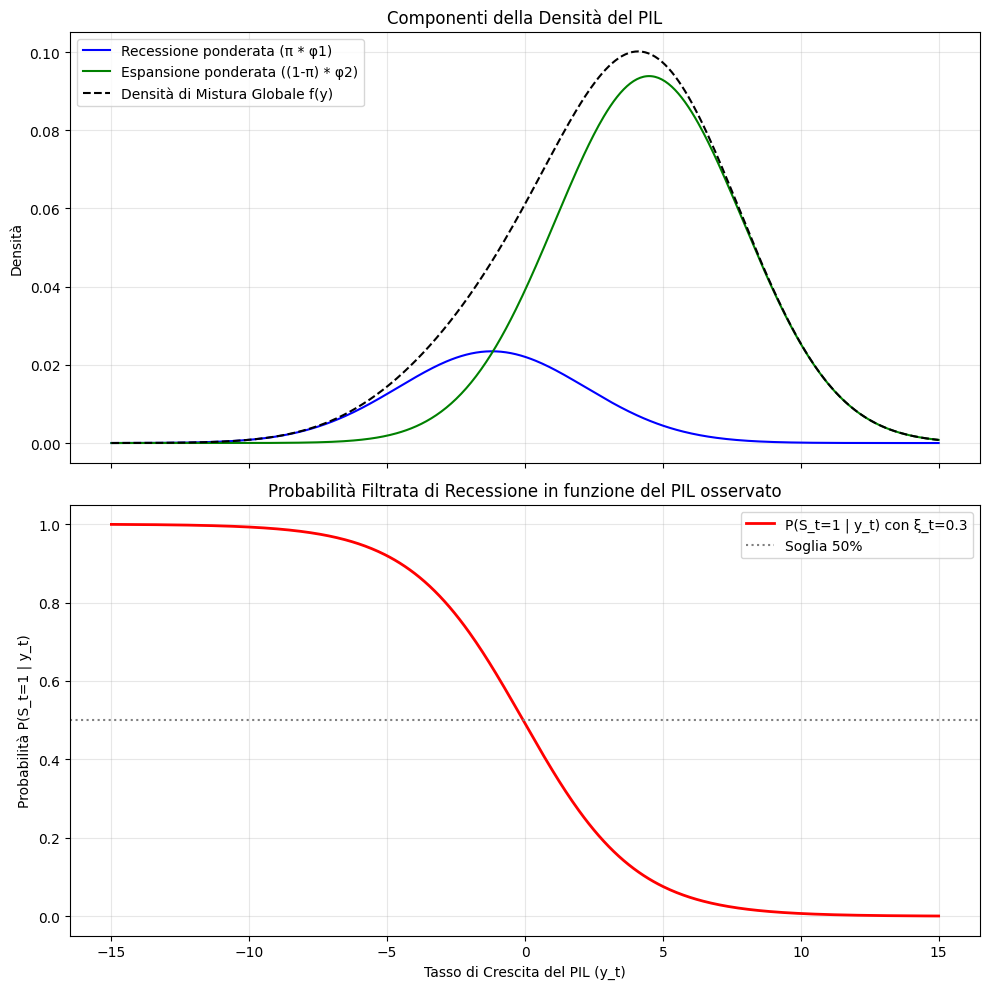

In [10]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt

# 1. Parametri del modello dal paper
mu_1 = -1.2  # Media in recessione
mu_2 = 4.5   # Media in espansione
sigma = 3.4  # Deviazione standard
pi = 0.2     # Probabilità incondizionata storicamente (20%)
xi_t = 0.3   # Esempio di probabilità a priori (inerzia dal periodo t-1)

# 2. Generazione dei valori per il tasso di crescita del PIL (y_t)
y_values = np.linspace(-15, 15, 500)

# 3. Calcolo delle densità
phi_1 = stats.norm.pdf(y_values, mu_1, sigma)
phi_2 = stats.norm.pdf(y_values, mu_2, sigma)
mixture_density = pi * phi_1 + (1 - pi) * phi_2

# 4. Calcolo della Probabilità Filtrata P(S_t = 1 | y_t)
numerator = xi_t * phi_1
denominator = numerator + (1 - xi_t) * phi_2
filtered_prob = numerator / denominator

# 5. Creazione dei grafici
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 10), sharex=True)

# Grafico Superiore: Densità e Mistura
ax1.plot(y_values, pi * phi_1, 'b-', label='Recessione ponderata (π * φ1)')
ax1.plot(y_values, (1 - pi) * phi_2, 'g-', label='Espansione ponderata ((1-π) * φ2)')
ax1.plot(y_values, mixture_density, 'k--', label='Densità di Mistura Globale f(y)')
ax1.set_title("Componenti della Densità del PIL")
ax1.set_ylabel("Densità")
ax1.legend()
ax1.grid(alpha=0.3)

# Grafico Inferiore: Probabilità Filtrata (Inferenza Bayesiana)
ax2.plot(y_values, filtered_prob, 'r-', linewidth=2, label=f'P(S_t=1 | y_t) con ξ_t={xi_t}')
ax2.axhline(0.5, color='gray', linestyle=':', label='Soglia 50%')
ax2.set_title("Probabilità Filtrata di Recessione in funzione del PIL osservato")
ax2.set_xlabel("Tasso di Crescita del PIL (y_t)")
ax2.set_ylabel("Probabilità P(S_t=1 | y_t)")
ax2.legend()
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Il Modello a Cambiamenti di Regime (Markov-Switching) per l'identificazione delle Recessioni

Nel paper *"Calling Recessions in Real Time"* (Hamilton, 2010), il ciclo economico è trattato come uno stato inosservato (nascosto) dell'economia. In ogni trimestre, l'economia può trovarsi in uno di due stati:
*   $S_t = 1$: **Recessione** (dove il tasso di crescita del PIL $y_t$ segue una distribuzione normale con media negativa: $y_t \sim \mathcal{N}(\mu_1, \sigma^2)$)
*   $S_t = 2$: **Espansione** (dove il PIL segue una distribuzione con media positiva: $y_t \sim \mathcal{N}(\mu_2, \sigma^2)$)

Per stabilire in tempo reale in quale stato ci troviamo, il modello utilizza un meccanismo di aggiornamento Bayesiano.

#### Il ruolo della "Prior" (Probabilità a Priori): $\xi_t$
In questo contesto, la **prior** è rappresentata dalla variabile **$\xi_t$**. 
Essa rappresenta la probabilità che l'economia sia in recessione nel trimestre corrente $t$ **prima** che venga pubblicato il dato effettivo sul PIL ($y_t$).

Questa probabilità a priori non è statica, ma viene derivata matematicamente dal trimestre precedente ($t-1$). Incapsula tutta l'**inerzia** del ciclo economico (una recessione tende a durare per più trimestri, così come un'espansione). Si calcola usando le probabilità di transizione storiche (es. la probabilità che una recessione continui, $p_{11}$):

$$ \xi_t = p_{11} P(S_{t-1} = 1 | y_{t-1}, ...) + (1-p_{22}) P(S_{t-1} = 2 | y_{t-1}, ...) $$

#### L'Aggiornamento Bayesiano (Probabilità Filtrata a Posteriori)
Quando finalmente osserviamo il dato del PIL odierno ($y_t$), utilizziamo la prior ($\xi_t$) come peso per calcolare la **probabilità filtrata** finale (la probabilità a posteriori).

Il modello confronta la probabilità che il dato $y_t$ provenga dalla campana della recessione ($\phi_1$) rispetto a quella dell'espansione ($\phi_2$), soppesandole con la prior:

$$ P(S_t = 1 | y_t, y_{t-1}, ...) = \frac{\xi_t \phi(y_t; \mu_1, \sigma)}{\xi_t \phi(y_t; \mu_1, \sigma) + (1-\xi_t)\phi(y_t; \mu_2, \sigma)} $$

**In sintesi:** 
La prior ($\xi_t$) funge da "memoria del sistema". Se l'inerzia ereditata dal mese scorso è alta ($\xi_t \approx 0.8$), il sistema parte già dal presupposto di essere in recessione. A causa di questa prior, servirà un dato del PIL $y_t$ straordinariamente positivo per convincere il modello a far scendere la probabilità filtrata sotto il 50% e dichiarare terminata la recessione.

/Users/certideal/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(
/Users/certideal/Library/Python/3.9/lib/python/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency QS-OCT will be used.
  self._init_dates(dates, freq)


=== PARAMETRI STRUTTURALI CHE GOVERNANO LA SERIE ===
Regime 0 (Bassa Crescita/Recessione) -> Media: 2.96%, Varianza: 3.28
Regime 1 (Alta Crescita/Espansione)  -> Media: 2.54%, Varianza: 59.06

=== MATRICE DI TRANSIZIONE (Inerzia) ===
Probabilità di restare in Regime 0: 95.8%
Probabilità di restare in Regime 1: 0.0%


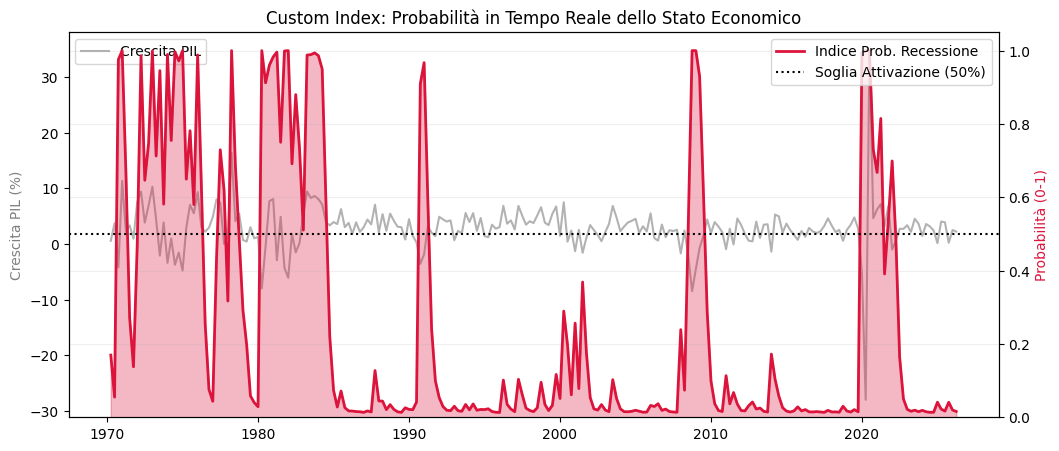

In [11]:
import pandas as pd
import numpy as np
import pandas_datareader.data as web
import statsmodels.api as sm
import matplotlib.pyplot as plt
import datetime

# 1. Scarichiamo la serie storica (Esempio: PIL Reale USA)
start_date = datetime.datetime(1970, 1, 1)
end_date = datetime.datetime.today()
gdp = web.DataReader('GDPC1', 'fred', start_date, end_date)

# Calcoliamo il tasso di crescita percentuale trimestrale annualizzato
gdp_growth = ((gdp['GDPC1'] / gdp['GDPC1'].shift(1)) ** 4 - 1) * 100
gdp_growth = gdp_growth.dropna()

# 2. Costruzione del Motore dell'Indice Custom (Markov-Switching Model)
# Ipotizziamo 2 stati latenti (es. Espansione e Recessione) con varianze diverse
model = sm.tsa.MarkovRegression(gdp_growth, k_regimes=2, trend='c', switching_variance=True)
result = model.fit(method='bfgs', search_reps=20)

# 3. Estrazione dei Parametri Governanti
print("=== PARAMETRI STRUTTURALI CHE GOVERNANO LA SERIE ===")
params = result.params
print(f"Regime 0 (Bassa Crescita/Recessione) -> Media: {params['const[0]']:.2f}%, Varianza: {params['sigma2[0]']:.2f}")
print(f"Regime 1 (Alta Crescita/Espansione)  -> Media: {params['const[1]']:.2f}%, Varianza: {params['sigma2[1]']:.2f}")

# Matrice di transizione (Inerzia del sistema)
p00 = params.get('p[0->0]', 0) # Prob. di restare nel regime 0
p11 = params.get('p[1->1]', 0) # Prob. di restare nel regime 1
print("\n=== MATRICE DI TRANSIZIONE (Inerzia) ===")
print(f"Probabilità di restare in Regime 0: {p00 * 100:.1f}%")
print(f"Probabilità di restare in Regime 1: {p11 * 100:.1f}%")

# 4. Costruzione dell'Indice Custom (Probabilità Filtrata)
# Selezioniamo il regime con la media più bassa come "Regime di Rischio" (Recessione)
risk_regime = 0 if params['const[0]'] < params['const[1]'] else 1
custom_index = result.filtered_marginal_probabilities[risk_regime]

# 5. Visualizzazione del Custom Index
fig, ax = plt.subplots(figsize=(12, 5))

# Plot della serie grezza
ax.plot(gdp_growth.index, gdp_growth, color='gray', alpha=0.6, label='Crescita PIL')
ax.set_ylabel('Crescita PIL (%)', color='gray')

# Plot dell'Indice di Probabilità sul secondo asse
ax2 = ax.twinx()
ax2.plot(custom_index.index, custom_index, color='crimson', linewidth=2, label='Indice Prob. Recessione')
ax2.fill_between(custom_index.index, 0, custom_index, color='crimson', alpha=0.3)
ax2.set_ylabel('Probabilità (0-1)', color='crimson')
ax2.set_ylim(0, 1.05)
ax2.axhline(0.5, color='black', linestyle=':', label='Soglia Attivazione (50%)')

plt.title('Custom Index: Probabilità in Tempo Reale dello Stato Economico')
ax.legend(loc='upper left')
ax2.legend(loc='upper right')
plt.grid(alpha=0.2)
plt.show()

# Forecasting nelle Serie Storiche: Modelli AR e MA


In [12]:
import numpy as np
import matplotlib.pyplot as plt

# Setup per i grafici
plt.style.use('seaborn-v0_8-darkgrid')
np.random.seed(42)

## 1. Modelli AR(1) e AR(p): Previsione a 1 step ahead

### Modello AR(1)
Un processo AR(1) è definito come:
$$X_t = c + \phi X_{t-1} + \epsilon_t$$
dove $c$ è una costante, $\phi$ è il parametro autoregressivo e $\epsilon_t \sim WN(0, \sigma^2)$ è il White Noise.

L'operatore di previsione (valore atteso condizionato all'informazione disponibile al tempo $t$) per un passo in avanti ($1$-step ahead) è:
$$\hat{X}_{t+1|t} = \mathbb{E}[X_{t+1} | \mathcal{F}_t] = \mathbb{E}[c + \phi X_t + \epsilon_{t+1} | \mathcal{F}_t] = c + \phi X_t$$
Poiché $\epsilon_{t+1}$ non è ancora avvenuto, il suo valore atteso è 0. L'errore di previsione è semplicemente $\epsilon_{t+1}$.

### Modello AR(p)
Un processo AR(p) dipende dai $p$ return precedenti:
$$X_t = c + \phi_1 X_{t-1} + \dots + \phi_p X_{t-p} + \epsilon_t$$

La previsione a $1$-step ahead estende la logica dell'AR(1) includendo i $p$ valori osservati:
$$\hat{X}_{t+1|t} = c + \phi_1 X_t + \phi_2 X_{t-1} + \dots + \phi_p X_{t-p+1}$$

Valore reale al tempo t=99: 6.50
Previsione 1-step ahead per t=100: 6.55
Valore reale al tempo t=99: 6.50
Previsione 1-step ahead (t=100): 6.55
Intervallo di confidenza al 95%: [4.59, 8.51]


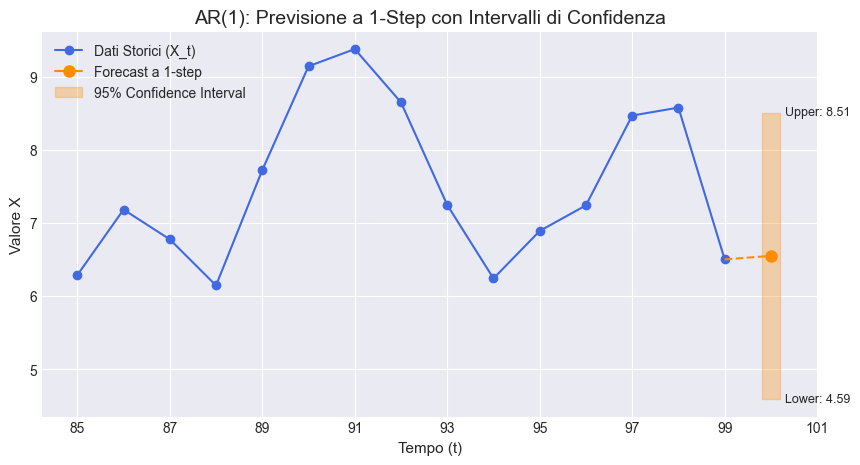

In [18]:
# Simulazione di un AR(1)
n = 100
c = 2.0
phi = 0.7
sigma = 1.0

# Generiamo la serie
epsilon = np.random.normal(0, sigma, n)
X_ar1 = np.zeros(n)
X_ar1[0] = c / (1 - phi) # Partenza dal valore medio incondizionato

for t in range(1, n):
    X_ar1[t] = c + phi * X_ar1[t-1] + epsilon[t]

# Forecast 1-step ahead dal tempo n-1 al tempo n
t_origin = n - 1
X_t = X_ar1[t_origin]

forecast_1_step = c + phi * X_t
print(f"Valore reale al tempo t={t_origin}: {X_t:.2f}")
print(f"Previsione 1-step ahead per t={t_origin+1}: {forecast_1_step:.2f}")

# -----------------------

# 1. Calcolo degli Intervalli di Confidenza (95%)
z_score = 1.96
margin_of_error = z_score * sigma

lower_bound = forecast_1_step - margin_of_error
upper_bound = forecast_1_step + margin_of_error

print(f"Valore reale al tempo t={t_origin}: {X_t:.2f}")
print(f"Previsione 1-step ahead (t={n}): {forecast_1_step:.2f}")
print(f"Intervallo di confidenza al 95%: [{lower_bound:.2f}, {upper_bound:.2f}]")

# 2. Visualizzazione su Grafico
# Selezioniamo solo gli ultimi 15 periodi per non "schiacciare" visivamente la previsione
lookback = 15 
time_storico = np.arange(n - lookback, n)
time_forecast = n

plt.figure(figsize=(10, 5))
plt.style.use('seaborn-v0_8-darkgrid')

# Plot della serie storica (ultimi 'lookback' periodi)
plt.plot(time_storico, X_ar1[-lookback:], marker='o', color='royalblue', label='Dati Storici (X_t)')

# Linea di connessione tra l'ultimo dato reale e la previsione
plt.plot([n-1, n], [X_ar1[-1], forecast_1_step], linestyle='--', color='darkorange')

# Plot del punto di previsione
plt.plot(time_forecast, forecast_1_step, marker='o', markersize=8, color='darkorange', label='Forecast a 1-step')

# Plot dell'intervallo di confidenza (area sfumata verticale)
plt.fill_between([time_forecast - 0.2, time_forecast + 0.2], 
                 lower_bound, upper_bound, 
                 color='darkorange', alpha=0.3, label='95% Confidence Interval')

# Aggiungiamo le etichette per i bound
plt.text(time_forecast + 0.3, upper_bound, f"Upper: {upper_bound:.2f}", va='center', fontsize=9)
plt.text(time_forecast + 0.3, lower_bound, f"Lower: {lower_bound:.2f}", va='center', fontsize=9)

plt.title('AR(1): Previsione a 1-Step con Intervalli di Confidenza', fontsize=14)
plt.xlabel('Tempo (t)', fontsize=11)
plt.ylabel('Valore X', fontsize=11)
plt.xticks(np.arange(n - lookback, n + 2, 2))
plt.legend(loc='upper left')
plt.show()

## 2. Modello AR(1): Previsione a 2 step ahead

Vogliamo prevedere il valore al tempo $t+2$ trovandoci al tempo $t$. Il processo è:
$$X_{t+2} = c + \phi X_{t+1} + \epsilon_{t+2}$$

Sostituendo iterativamente, la previsione diventa:
$$\hat{X}_{t+2|t} = \mathbb{E}[c + \phi X_{t+1} + \epsilon_{t+2} | \mathcal{F}_t] = c + \phi \hat{X}_{t+1|t}$$

Come si nota, la previsione a due passi utilizza la previsione a un passo calcolata in precedenza, non il valore reale $X_{t+1}$ (che al tempo $t$ è ignoto).
Espandendo il termine si ottiene:
$$\hat{X}_{t+2|t} = c + \phi(c + \phi X_t) = c + c\phi + \phi^2 X_t$$

## Calcolo e Grafico degli Intervalli di Confidenza (AR 2-step ahead)

Quando prevediamo a 2 passi nel futuro, l'incertezza aumenta. L'errore di previsione a 2 passi è:
$$e_{t+2} = X_{t+2} - \hat{X}_{t+2|t}$$

Sostituendo il processo reale espanso ($X_{t+2} = c + c\phi + \phi^2 X_t + \epsilon_{t+2} + \phi\epsilon_{t+1}$) e la nostra previsione ($\hat{X}_{t+2|t} = c + c\phi + \phi^2 X_t$), otteniamo:
$$e_{t+2} = \epsilon_{t+2} + \phi \epsilon_{t+1}$$

Poiché i termini di errore (White Noise) sono indipendenti, la varianza dell'errore di previsione è la somma delle loro varianze:
$$Var(e_{t+2}) = Var(\epsilon_{t+2}) + Var(\phi \epsilon_{t+1}) = \sigma^2 + \phi^2 \sigma^2 = \sigma^2(1 + \phi^2)$$

La deviazione standard (Standard Error) per il 2-step ahead è quindi $\sigma \sqrt{1 + \phi^2}$. 
Poiché per un processo stazionario $|\phi| < 1$, si ha $(1 + \phi^2) > 1$. Di conseguenza, **l'intervallo di confidenza al passo 2 è più largo rispetto al passo 1**.

L'intervallo di confidenza al 95% si calcola come:
$$[\hat{X}_{t+2|t} - 1.96\sigma\sqrt{1 + \phi^2} \;, \; \hat{X}_{t+2|t} + 1.96\sigma\sqrt{1 + \phi^2}]$$

Previsione 2-step ahead (Metodo iterativo): 6.59
Previsione 2-step ahead (Metodo espanso): 6.59
Previsione 1-step (t=100):   6.55 | Intervallo 95%: [4.59, 8.51] (Ampiezza: 3.92)
Previsione 2-step (t=101): 6.59 | Intervallo 95%: [4.19, 8.98] (Ampiezza: 4.78)


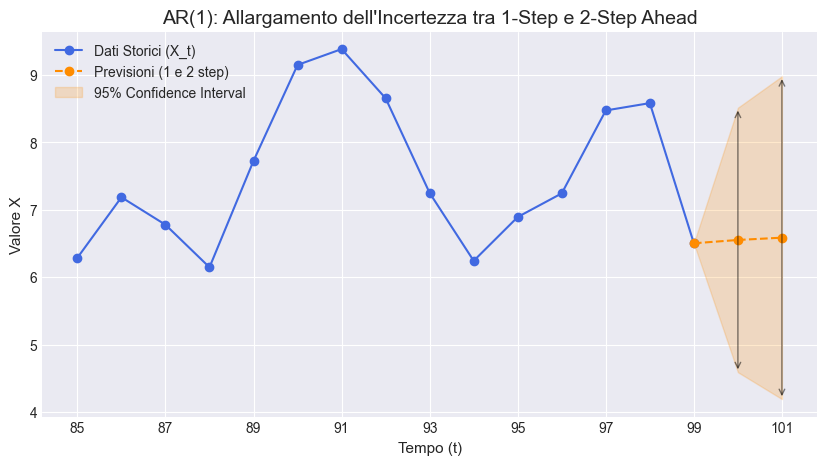

In [19]:
# Forecast 2-step ahead dal tempo n-1 al tempo n+1
forecast_2_step = c + phi * forecast_1_step

# Metodo alternativo usando l'espansione matematica
forecast_2_step_alt = c + c * phi + (phi**2) * X_t

print(f"Previsione 2-step ahead (Metodo iterativo): {forecast_2_step:.2f}")
print(f"Previsione 2-step ahead (Metodo espanso): {forecast_2_step_alt:.2f}")

# Varianza e deviazione standard (Standard Error) per 2-step
variance_2_step = (sigma**2) * (1 + phi**2)
se_2_step = np.sqrt(variance_2_step)

margin_of_error_2 = z_score * se_2_step
lower_bound_2 = forecast_2_step - margin_of_error_2
upper_bound_2 = forecast_2_step + margin_of_error_2

print(f"Previsione 1-step (t={n}):   {forecast_1_step:.2f} | Intervallo 95%: [{lower_bound:.2f}, {upper_bound:.2f}] (Ampiezza: {upper_bound-lower_bound:.2f})")
print(f"Previsione 2-step (t={n+1}): {forecast_2_step:.2f} | Intervallo 95%: [{lower_bound_2:.2f}, {upper_bound_2:.2f}] (Ampiezza: {upper_bound_2-lower_bound_2:.2f})")

# 2. Preparazione dei dati per il grafico "a cono" (Fan Chart)
time_storico = np.arange(n - 15, n)
time_forecast = np.array([n - 1, n, n + 1]) # Includiamo t per connettere graficamente il "cono" di incertezza

# I valori centrali includono l'ultimo dato reale, poi le previsioni
forecast_path = np.array([X_ar1[-1], forecast_1_step, forecast_2_step])

# Gli intervalli partono da larghezza 0 al tempo t (il dato è noto)
lower_path = np.array([X_ar1[-1], lower_bound, lower_bound_2])
upper_path = np.array([X_ar1[-1], upper_bound, upper_bound_2])

# 3. Creazione del grafico
plt.figure(figsize=(10, 5))
plt.style.use('seaborn-v0_8-darkgrid')

# Dati storici
plt.plot(time_storico, X_ar1[-15:], marker='o', color='royalblue', label='Dati Storici (X_t)')

# Linea di previsione
plt.plot(time_forecast, forecast_path, marker='o', linestyle='--', color='darkorange', label='Previsioni (1 e 2 step)')

# Area di confidenza (Cone / Fan chart)
plt.fill_between(time_forecast, lower_path, upper_path, color='darkorange', alpha=0.2, label='95% Confidence Interval')

# Aggiunta di annotazioni per mostrare l'allargamento
plt.annotate('', xy=(n, upper_bound), xytext=(n, lower_bound),
            arrowprops=dict(arrowstyle='<->', color='black', alpha=0.5))
plt.annotate('', xy=(n+1, upper_bound_2), xytext=(n+1, lower_bound_2),
            arrowprops=dict(arrowstyle='<->', color='black', alpha=0.5))

plt.title('AR(1): Allargamento dell\'Incertezza tra 1-Step e 2-Step Ahead', fontsize=14)
plt.xlabel('Tempo (t)', fontsize=11)
plt.ylabel('Valore X', fontsize=11)
plt.xticks(np.arange(n - 15, n + 3, 2))
plt.legend(loc='upper left')
plt.show()

## 3. Modello AR(1): Previsione a l-step ahead

Generalizzando per un orizzonte temporale $l > 0$, la previsione si ottiene ricorsivamente:
$$\hat{X}_{t+l|t} = c + \phi \hat{X}_{t+l-1|t}$$

Espandendo la formula rispetto a $X_t$ si ottiene:
$$\hat{X}_{t+l|t} = c \sum_{i=0}^{l-1} \phi^i + \phi^l X_t$$

**Proprietà fondamentale (Mean Reversion):**
Se il processo è stazionario ($|\phi| < 1$), per $l \to \infty$, il termine $\phi^l \to 0$ e la sommatoria converge. La previsione di lungo periodo collassa sulla media incondizionata del processo $\mu = \frac{c}{1 - \phi}$.

Calcolo e Grafico degli Intervalli di Confidenza (AR l-step ahead)

Quando estendiamo la previsione a un orizzonte $l$ arbitrario, l'errore di previsione accumula tutti gli shock (White Noise) che si verificheranno tra il tempo $t+1$ e il tempo $t+l$. 
L'errore di previsione a $l$ passi è dato da:
$$e_{t+l} = X_{t+l} - \hat{X}_{t+l|t} = \sum_{i=0}^{l-1} \phi^i \epsilon_{t+l-i}$$

Poiché i termini $\epsilon$ sono indipendenti e hanno varianza $\sigma^2$, la varianza dell'errore di previsione a $l$ passi è la somma delle varianze pesate:
$$Var(e_{t+l}) = \sigma^2 \sum_{i=0}^{l-1} \phi^{2i} = \sigma^2 \left( \frac{1 - \phi^{2l}}{1 - \phi^2} \right)$$

**Proprietà asintotica (Incertezza di lungo periodo):**
Man mano che $l \to \infty$ (per un processo stazionario, $|\phi| < 1$), il termine $\phi^{2l} \to 0$. La varianza dell'errore di previsione converge alla varianza incondizionata del processo AR(1):
$$\lim_{l \to \infty} Var(e_{t+l}) = \frac{\sigma^2}{1 - \phi^2}$$

Questo significa che l'intervallo di confidenza si allarga progressivamente, ma non cresce all'infinito: si stabilizza attorno a un limite massimo (la banda di variabilità intrinseca della serie storica). L'intervallo al 95% per il generico passo $l$ è:
$$[\hat{X}_{t+l|t} - 1.96\sqrt{Var(e_{t+l})} \;, \; \hat{X}_{t+l|t} + 1.96\sqrt{Var(e_{t+l})}]$$

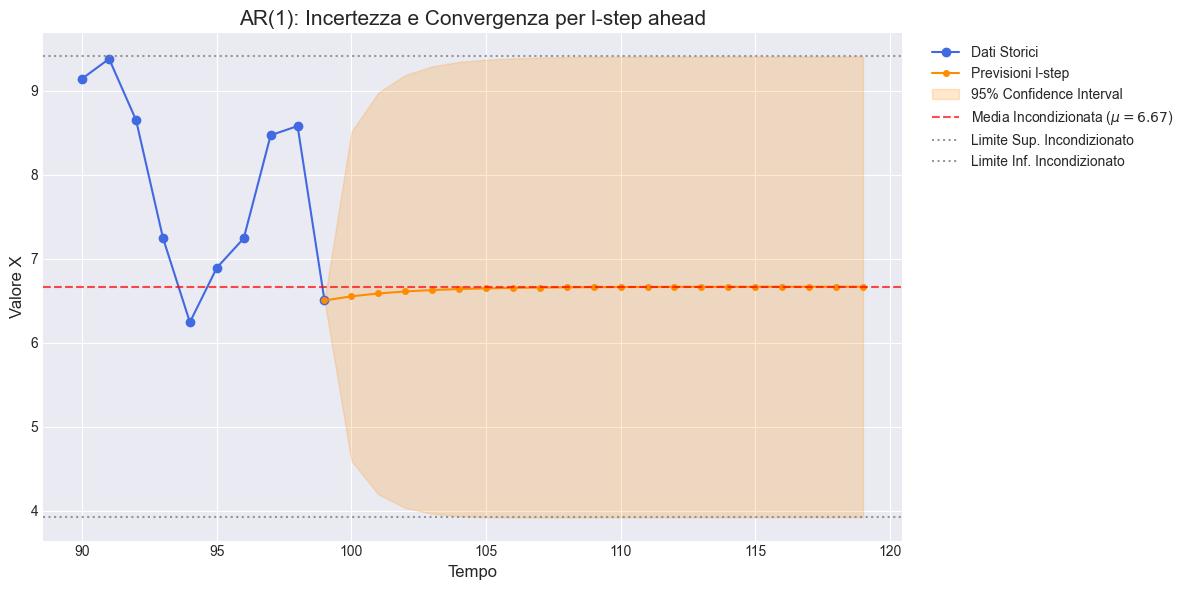

In [20]:
l_steps = 20
forecasts = np.zeros(l_steps)
variances = np.zeros(l_steps)

# Inizializzazione 1-step ahead
forecasts[0] = c + phi * X_ar1[-1]
variances[0] = sigma**2

# Calcolo ricorsivo per forecast e varianze l-step ahead
for l in range(1, l_steps):
    forecasts[l] = c + phi * forecasts[l-1]
    # La varianza aggiunge il nuovo termine di shock pesato
    variances[l] = variances[l-1] + (sigma**2) * (phi**(2*l))

# Calcolo dei limiti dell'intervallo di confidenza
standard_errors = np.sqrt(variances)
lower_bounds = forecasts - z_score * standard_errors
upper_bounds = forecasts + z_score * standard_errors

# Valori asintotici incondizionati (limiti per l -> infinito)
mean_unconditional = c / (1 - phi)
var_unconditional = (sigma**2) / (1 - phi**2)
se_unconditional = np.sqrt(var_unconditional)

asymptotic_upper = mean_unconditional + z_score * se_unconditional
asymptotic_lower = mean_unconditional - z_score * se_unconditional

# Preparazione vettori per il grafico "a cono" continuo con i dati storici
time_storico = np.arange(n - 10, n)
time_forecast = np.arange(n, n + l_steps)

time_full = np.concatenate(([n-1], time_forecast))
forecast_full = np.concatenate(([X_ar1[-1]], forecasts))
lower_full = np.concatenate(([X_ar1[-1]], lower_bounds))
upper_full = np.concatenate(([X_ar1[-1]], upper_bounds))

# Creazione del Grafico
plt.figure(figsize=(12, 6))
plt.style.use('seaborn-v0_8-darkgrid')

# 1. Dati storici
plt.plot(time_storico, X_ar1[-10:], marker='o', color='royalblue', label='Dati Storici')

# 2. Forecast puntuale
plt.plot(time_full, forecast_full, marker='o', markersize=4, linestyle='-', color='darkorange', label='Previsioni l-step')

# 3. Intervallo di confidenza (Cono)
plt.fill_between(time_full, lower_full, upper_full, color='darkorange', alpha=0.2, label='95% Confidence Interval')

# 4. Limiti Asintotici (Incondizionati)
plt.axhline(mean_unconditional, color='red', linestyle='--', alpha=0.7, 
            label=f'Media Incondizionata ($\mu={mean_unconditional:.2f}$)')
plt.axhline(asymptotic_upper, color='gray', linestyle=':', alpha=0.8, 
            label='Limite Sup. Incondizionato')
plt.axhline(asymptotic_lower, color='gray', linestyle=':', alpha=0.8, 
            label='Limite Inf. Incondizionato')

plt.title("AR(1): Incertezza e Convergenza per l-step ahead", fontsize=15)
plt.xlabel("Tempo", fontsize=12)
plt.ylabel("Valore X", fontsize=12)
plt.legend(loc='upper left', bbox_to_anchor=(1.02, 1)) # Sposta la legenda fuori per pulizia
plt.tight_layout()
plt.show()

## 4. Modelli MA(1) e MA(q): Previsioni a 1-step e l-step ahead

### Modello MA(1)
Un processo MA(1) dipende dal White Noise corrente e dal passato immediato:
$$X_t = \mu + \epsilon_t + \theta \epsilon_{t-1}$$

*   **1-step ahead ($l=1$):**
    $\hat{X}_{t+1|t} = \mathbb{E}[\mu + \epsilon_{t+1} + \theta \epsilon_t | \mathcal{F}_t] = \mu + \theta \epsilon_t$
    *(Assumendo che gli shock passati $\epsilon_t$ siano osservabili al tempo $t$ ricavandoli dai dati).*

*   **l-step ahead ($l > 1$):**
    $\hat{X}_{t+l|t} = \mathbb{E}[\mu + \epsilon_{t+l} + \theta \epsilon_{t+l-1} | \mathcal{F}_t] = \mu + 0 + 0 = \mu$
    *(Poiché l'informazione "muore" dopo 1 lag, tutte le previsioni oltre il primo passo collassano istantaneamente sulla media $\mu$).*

### Modello MA(q)
Un processo MA(q) possiede "memoria" lunga $q$ periodi:
$$X_t = \mu + \epsilon_t + \theta_1 \epsilon_{t-1} + \dots + \theta_q \epsilon_{t-q}$$

*   **1-step ahead ($l=1$):**
    $\hat{X}_{t+1|t} = \mu + \theta_1 \epsilon_t + \theta_2 \epsilon_{t-1} + \dots + \theta_q \epsilon_{t-q+1}$
*   **l-step ahead ($l \le q$):**
    Il forecast contiene i termini $\theta_i \epsilon_{t+l-i}$ per cui l'indice del tempo del White Noise è $\le t$.
*   **l-step ahead ($l > q$):**
    $\hat{X}_{t+l|t} = \mu$ (taglio netto della memoria: tutte le previsioni oltre il lag $q$ sono pari alla media).

A differenza dei modelli Autoregressivi (AR), in cui l'incertezza cresce progressivamente e converge in modo asintotico al limite incondizionato, **nei modelli a Media Mobile (MA) la varianza dell'errore raggiunge il suo massimo (la varianza incondizionata) esattamente dopo $q$ periodi**.

Prendiamo in esame il modello MA(2): 
$$X_t = \mu + \epsilon_t + \theta_1 \epsilon_{t-1} + \theta_2 \epsilon_{t-2}$$

Vediamo come si calcolano gli errori di previsione per i diversi orizzonti temporali:

*   **1-step ahead ($l=1$):**
    L'errore è dato unicamente dallo shock futuro $\epsilon_{t+1}$.
    $$Var(e_{t+1}) = Var(\epsilon_{t+1}) = \sigma^2$$

*   **2-step ahead ($l=2$):**
    L'errore accumula il nuovo shock $\epsilon_{t+2}$ e la propagazione dello shock precedente $\theta_1\epsilon_{t+1}$.
    $$Var(e_{t+2}) = Var(\epsilon_{t+2} + \theta_1 \epsilon_{t+1}) = \sigma^2(1 + \theta_1^2)$$

*   **3-step ahead e oltre ($l > q$, in questo caso $l \ge 3$):**
    La memoria del processo si esaurisce. L'errore è la varianza totale incondizionata del processo.
    $$Var(e_{t+l}) = Var(\epsilon_{t+l} + \theta_1 \epsilon_{t+l-1} + \theta_2 \epsilon_{t+l-2}) = \sigma^2(1 + \theta_1^2 + \theta_2^2)$$

Dal passo $q+1$ in poi, **l'intervallo di confidenza smette di allargarsi** e diventa costante.

=== Modello MA(2) ===
Previsione 1-step ahead: 10.70
Previsione 2-step ahead (ultimo ritardo visibile): 10.25
Previsione 3-step ahead (l > q, collassa sulla media): 10.00


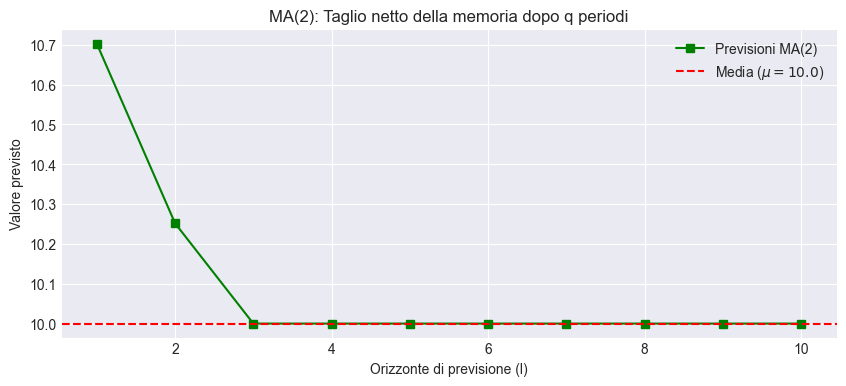

In [25]:
# Simulazione di un MA(2) - che funge da esempio per MA(q)
mu = 10.0
theta1 = 0.6
theta2 = 0.4
q = 2

# Generiamo il White Noise
epsilon_ma = np.random.normal(0, 1, n)
X_maq = np.zeros(n)

# Generazione della serie MA(2)
for t in range(2, n):
    X_maq[t] = mu + epsilon_ma[t] + theta1 * epsilon_ma[t-1] + theta2 * epsilon_ma[t-2]

# Assumiamo di essere al tempo n-1
t_origin = n - 1

# Forecast 1-step ahead
forecast_ma_1 = mu + theta1 * epsilon_ma[t_origin] + theta2 * epsilon_ma[t_origin-1]

# Forecast 2-step ahead (l = q)
forecast_ma_2 = mu + theta2 * epsilon_ma[t_origin]

# Forecast 3-step ahead (l > q)
forecast_ma_3 = mu

print("=== Modello MA(2) ===")
print(f"Previsione 1-step ahead: {forecast_ma_1:.2f}")
print(f"Previsione 2-step ahead (ultimo ritardo visibile): {forecast_ma_2:.2f}")
print(f"Previsione 3-step ahead (l > q, collassa sulla media): {forecast_ma_3:.2f}")

# Plot dell'orizzonte di previsione per MA(q)
l_steps_ma = 10
forecasts_ma = [forecast_ma_1, forecast_ma_2] + [mu]*(l_steps_ma - 2)

plt.figure(figsize=(10, 4))
plt.plot(range(1, l_steps_ma+1), forecasts_ma, marker='s', color='green', label='Previsioni MA(2)')
plt.axhline(mu, color='red', linestyle='--', label=f'Media ($\mu={mu}$)')
plt.title("MA(2): Taglio netto della memoria dopo q periodi")
plt.xlabel("Orizzonte di previsione (l)")
plt.ylabel("Valore previsto")
plt.legend()
plt.show()

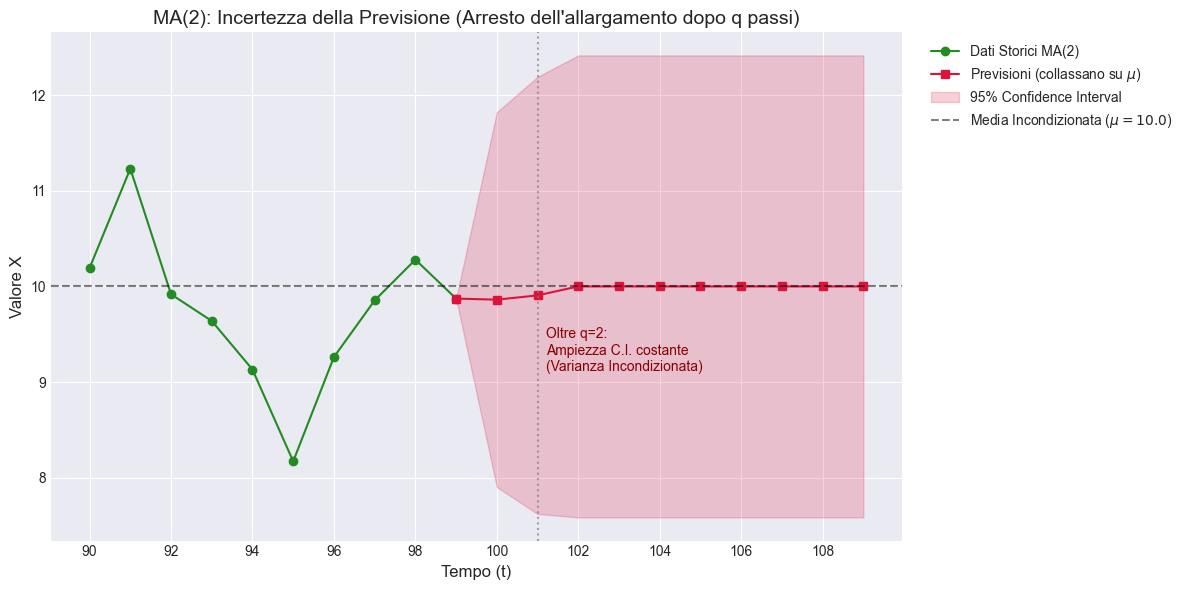

In [23]:
import numpy as np
import matplotlib.pyplot as plt

# --- Setup Dati Iniziali ---
np.random.seed(42)
n = 100
mu = 10.0
theta1 = 0.6
theta2 = 0.4
q = 2
sigma_ma = 1.0 # Varianza del White Noise

epsilon_ma = np.random.normal(0, sigma_ma, n)
X_maq = np.zeros(n)

# Generazione della serie MA(2)
for t in range(2, n):
    X_maq[t] = mu + epsilon_ma[t] + theta1 * epsilon_ma[t-1] + theta2 * epsilon_ma[t-2]

t_origin = n - 1

# Calcolo Previsioni
forecast_ma_1 = mu + theta1 * epsilon_ma[t_origin] + theta2 * epsilon_ma[t_origin-1]
forecast_ma_2 = mu + theta2 * epsilon_ma[t_origin]
forecast_ma_3 = mu

l_steps_ma = 10
forecasts_ma = np.array([forecast_ma_1, forecast_ma_2] + [mu]*(l_steps_ma - 2))

# --- Calcolo Intervalli di Confidenza ---
z_score = 1.96
variances_ma = np.zeros(l_steps_ma)

# Varianza 1-step
variances_ma[0] = sigma_ma**2
# Varianza 2-step
variances_ma[1] = (sigma_ma**2) * (1 + theta1**2)
# Varianza per l > q (3-step in poi) - Costante
var_unconditional_ma = (sigma_ma**2) * (1 + theta1**2 + theta2**2)
variances_ma[2:] = var_unconditional_ma

# Deviazione standard e limiti (bounds)
se_ma = np.sqrt(variances_ma)
lower_bounds_ma = forecasts_ma - z_score * se_ma
upper_bounds_ma = forecasts_ma + z_score * se_ma

# --- Preparazione Array per il Grafico (Continuità con il passato) ---
time_storico = np.arange(n - 10, n)
time_forecast = np.arange(n, n + l_steps_ma)

time_full = np.concatenate(([n-1], time_forecast))
forecast_full = np.concatenate(([X_maq[t_origin]], forecasts_ma))
lower_full = np.concatenate(([X_maq[t_origin]], lower_bounds_ma))
upper_full = np.concatenate(([X_maq[t_origin]], upper_bounds_ma))

# --- Creazione del Grafico ---
plt.figure(figsize=(12, 6))
plt.style.use('seaborn-v0_8-darkgrid')

# Dati storici
plt.plot(time_storico, X_maq[-10:], marker='o', color='forestgreen', label='Dati Storici MA(2)')

# Linea di previsione
plt.plot(time_full, forecast_full, marker='s', linestyle='-', color='crimson', label='Previsioni (collassano su $\mu$)')

# Area di confidenza
plt.fill_between(time_full, lower_full, upper_full, color='crimson', alpha=0.2, label='95% Confidence Interval')

# Linea della media incondizionata
plt.axhline(mu, color='black', linestyle='--', alpha=0.5, label=f'Media Incondizionata ($\mu={mu}$)')

# Annotazioni per evidenziare il comportamento MA
plt.axvline(x=n + 1, color='gray', linestyle=':', alpha=0.7)
plt.text(n + 1.2, upper_bounds_ma[2] - 3.3, "Oltre q=2:\nAmpiezza C.I. costante\n(Varianza Incondizionata)", fontsize=10, color='darkred')

plt.title("MA(2): Incertezza della Previsione (Arresto dell'allargamento dopo q passi)", fontsize=14)
plt.xlabel("Tempo (t)", fontsize=12)
plt.ylabel("Valore X", fontsize=12)
plt.xticks(np.arange(n - 10, n + l_steps_ma, 2))
plt.legend(loc='upper left', bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

## 5. ACF e PACF: Calcolo e Forma per i Modelli AR

La **ACF (Autocorrelation Function)** misura la correlazione lineare tra $X_t$ e i suoi ritardi $X_{t-k}$.
La **PACF (Partial Autocorrelation Function)** misura la correlazione tra $X_t$ e $X_{t-k}$ rimuovendo l'effetto lineare dei ritardi intermedi ($X_{t-1}, \dots, X_{t-k+1}$).

### Processo AR(1)
*   **ACF (Come si calcola):** L'autocovarianza al ritardo $k$ è $\gamma_k = \phi^k \gamma_0$. Dividendo per la varianza $\gamma_0$, l'autocorrelazione è:
    $$\rho_k = \phi^k$$
*   **Forma ACF:** Mostra un **decadimento esponenziale** (o oscillatorio smorzato se $\phi < 0$) verso lo zero, ma non si azzera mai completamente.
*   **PACF (Come si calcola):** L'unica dipendenza diretta "pura" è con il primo ritardo.
    $$\alpha_1 = \phi \quad \text{e} \quad \alpha_k = 0 \text{ per } k > 1$$
*   **Forma PACF:** Ha un **taglio netto (cut-off)** a zero dopo il ritardo $1$.

### Processo AR(p)
*   **ACF:** Decadimento esponenziale e/o sinusoidale smorzato (combinazione delle radici dell'equazione caratteristica).
*   **PACF:** Taglio netto a zero dopo il ritardo $p$. È lo strumento principale per identificare l'ordine $p$ di un modello AR.

## 6. ACF e PACF: Calcolo e Forma per i Modelli MA

I modelli MA hanno un comportamento esattamente speculare rispetto ai modelli AR.

### Processo MA(1): $X_t = \mu + \epsilon_t + \theta \epsilon_{t-1}$
*   **ACF (Come si calcola):** La covarianza esiste solo tra osservazioni distanti 1 periodo, poiché il White Noise è indipendente.
    $$\rho_1 = \frac{\theta}{1 + \theta^2} \quad \text{e} \quad \rho_k = 0 \text{ per } k > 1$$
*   **Forma ACF:** Ha un **taglio netto (cut-off)** a zero dopo il ritardo $1$.
*   **PACF (Forma):** Mostra un **decadimento esponenziale** (o sinusoidale smorzato) asintotico verso lo zero. Non si azzera mai del tutto perché un MA(1) invertibile può essere riscritto come un AR($\infty$).

### Processo MA(q)
*   **ACF:** Taglio netto a zero dopo il ritardo $q$. È lo strumento principale per identificare l'ordine $q$ di un modello MA.
*   **PACF:** Decadimento esponenziale e/o sinusoidale smorzato.

---

### Tabella Riassuntiva per l'identificazione

| Modello | Forma ACF | Forma PACF |
| :--- | :--- | :--- |
| **AR(p)** | Decadimento (esponenziale o oscillatorio) | **Taglio a zero dopo il lag $p$** |
| **MA(q)** | **Taglio a zero dopo il lag $q$** | Decadimento (esponenziale o oscillatorio) |
| **ARMA(p,q)** | Decadimento | Decadimento |

## 7. ACF e PACF della Traiettoria di Previsione ($l$-step ahead)

Cosa succede se calcoliamo l'ACF e la PACF direttamente sulla **sequenza delle previsioni future** $\hat{X}_{T+1}, \hat{X}_{T+2}, \dots, \hat{X}_{T+h}$?

È importante notare una differenza fondamentale rispetto ai dati storici: la traiettoria di previsione (il forecast) è **deterministica**, perché non contiene i futuri shock (White Noise), che hanno valore atteso pari a 0.

1. **Previsioni AR(2):** Il forecast di un modello AR(p) converge asintoticamente alla media seguendo la stessa esatta equazione alle differenze del processo (Equazioni di Yule-Walker). Di conseguenza, l'ACF della serie prevista mostrerà un decadimento ancora più "perfetto" e liscio rispetto ai dati storici, privo del rumore statistico.
2. **Previsioni MA(2):** Le previsioni di un modello MA(q) assumono valori non nulli solo per i primi $q$ passi, per poi collassare a zero (o alla media $\mu$). La sequenza sarà letteralmente `[val_1, val_2, 0, 0, 0, ...]`. La sua ACF/PACF confermerà semplicemente che, dopo il ritardo $q$, la serie diventa una costante piatta senza alcuna varianza o dinamica.

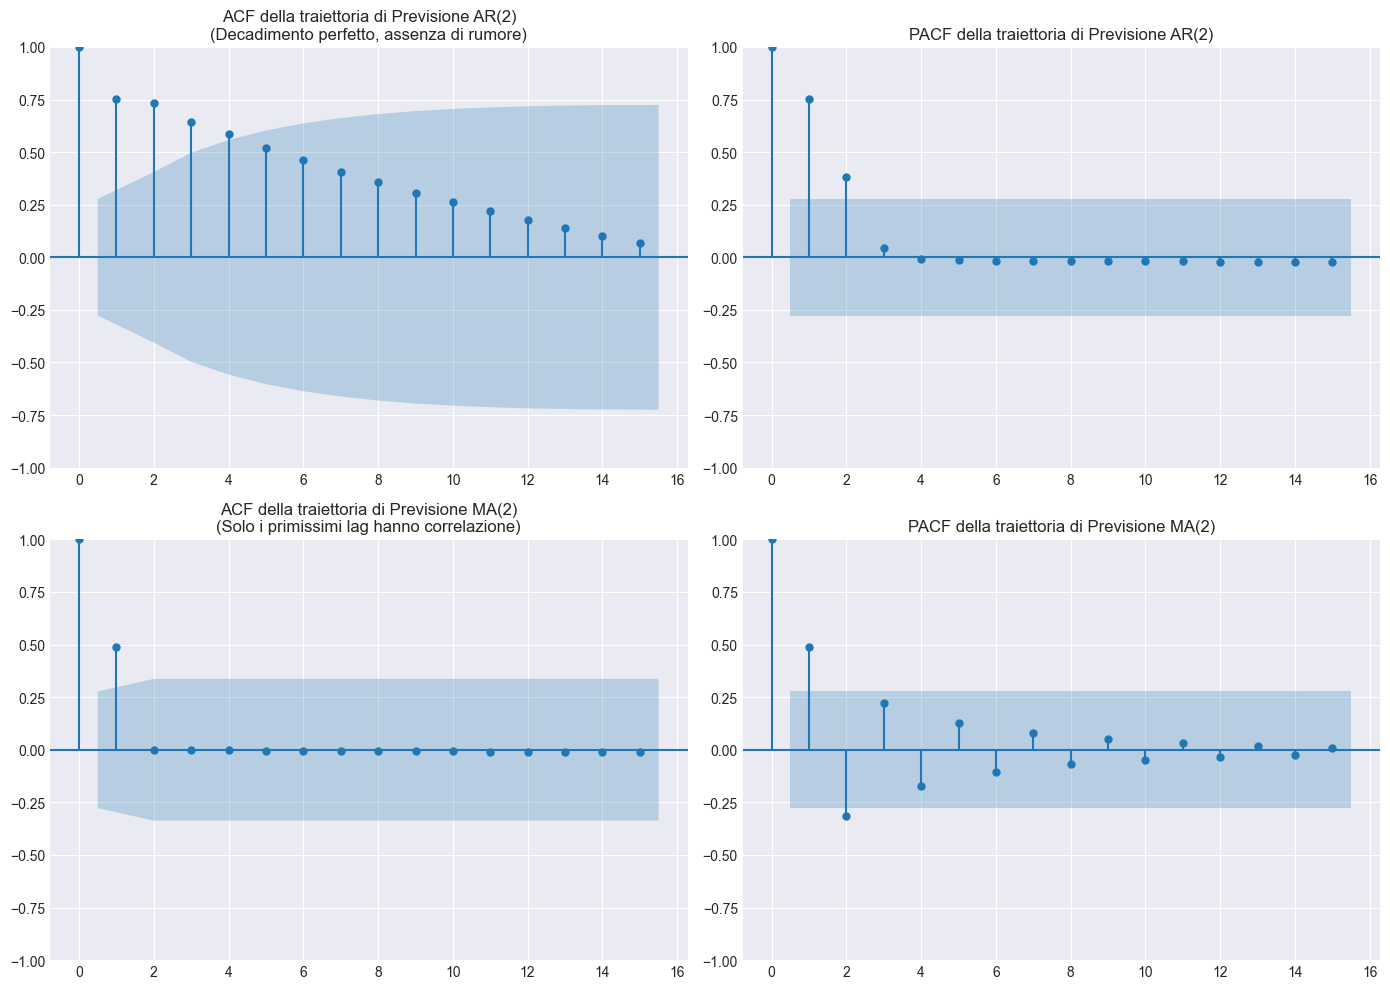

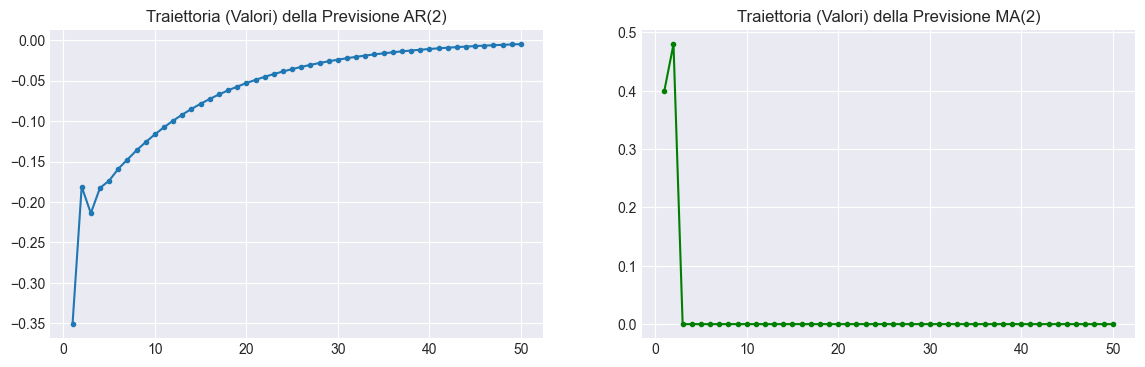

In [26]:
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import warnings
warnings.filterwarnings("ignore") # Ignora i warning sulle serie costanti per l'MA

# 1. Generazione delle traiettorie di previsione (50 passi in avanti)
h = 50
forecast_ar = np.zeros(h)
forecast_ma = np.zeros(h)

# --- Forecast AR(2) ---
# Parametri: phi1 = 0.6, phi2 = 0.3
# Usiamo gli ultimi due valori della serie y_ar simulata nella cella precedente
forecast_ar[0] = 0.6 * y_ar[-1] + 0.3 * y_ar[-2]
forecast_ar[1] = 0.6 * forecast_ar[0] + 0.3 * y_ar[-1]
for i in range(2, h):
    forecast_ar[i] = 0.6 * forecast_ar[i-1] + 0.3 * forecast_ar[i-2]

# --- Forecast MA(2) ---
# Parametri: theta1 = 0.5, theta2 = 0.4
# Per prevedere serve conoscere gli ultimi due shock (epsilon). Li simuliamo per l'esempio.
eps_T = 1.2
eps_T_minus_1 = -0.5

forecast_ma[0] = 0.5 * eps_T + 0.4 * eps_T_minus_1 # 1-step ahead
forecast_ma[1] = 0.4 * eps_T                       # 2-step ahead
# Da l=3 in poi (indice 2), il forecast MA(2) è zero (la media)
# forecast_ma[2:] rimane 0.0 come inizializzato

# 2. Creazione dei grafici (Correlogrammi sulle Previsioni)
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Grafici per le PREVISIONI AR(2)
# Nota: Essendo una sequenza liscia che decade, l'ACF sarà un decadimento perfetto.
plot_acf(forecast_ar, lags=15, ax=axes[0, 0], title="ACF della traiettoria di Previsione AR(2)\n(Decadimento perfetto, assenza di rumore)")
plot_pacf(forecast_ar, lags=15, ax=axes[0, 1], title="PACF della traiettoria di Previsione AR(2)", method='ywm')

# Grafici per le PREVISIONI MA(2)
# Nota: La serie è composta da 2 valori e poi tutti zeri. 
plot_acf(forecast_ma, lags=15, ax=axes[1, 0], title="ACF della traiettoria di Previsione MA(2)\n(Solo i primissimi lag hanno correlazione)")
plot_pacf(forecast_ma, lags=15, ax=axes[1, 1], title="PACF della traiettoria di Previsione MA(2)", method='ywm')

plt.tight_layout()
plt.show()

# Visualizziamo anche la forma effettiva delle due traiettorie per capire l'ACF
fig2, ax2 = plt.subplots(1, 2, figsize=(14, 4))
ax2[0].plot(range(1, h+1), forecast_ar, marker='.')
ax2[0].set_title("Traiettoria (Valori) della Previsione AR(2)")
ax2[1].plot(range(1, h+1), forecast_ma, marker='.', color='green')
ax2[1].set_title("Traiettoria (Valori) della Previsione MA(2)")
plt.show()